---
title: "Drugs: four questions about medication use"
subtitle: "From dispensing history to reviewable patient and spending opportunities"
author: "Tuva Health"
format:
  html:
    theme: cosmo
    embed-resources: true
    toc: true
    toc-depth: 2
    toc-title: "In this notebook"
    code-fold: true
    code-summary: "Show code"
    code-copy: true
    title-block-banner: "#0a0a0a"
    include-in-header:
      text: |
        <style>
        :root{--bs-primary:#216b91;} body{color:#182c38;font-size:17px;}
        h1,h2,h3{color:#0a0a0a;} .quarto-title-banner h1{color:white;}
        .cell-output-display{overflow-x:auto;} .figure-explanation{color:#506477;font-size:.92rem;}
        table{font-variant-numeric:tabular-nums;} a{color:#216b91;}
        </style>
execute:
  enabled: false
---

[Source on GitHub](https://github.com/tuva-health/drugs) · [Data mart documentation](https://thetuvaproject.com/data-marts/drugs)

A pharmacy claim tells us that a medication was dispensed. With the dispensing
date and days supply, we can estimate when that supply was available. Linking
those records to drug terminology and the patient's documented conditions
helps answer four practical questions:

1. **Drug Episodes:** How long has a person had an observed course of a drug?
2. **Open Drug Gaps:** Which patients have a relevant condition but no related
   medication supply active at the assessment date?
3. **Needs Refill:** Which established maintenance treatments appear due soon
   or recently overdue, and what share of each condition population is affected?
4. **Brand vs. Generic:** Which current brand users have a similar generic,
   and what payer-paid savings do comparable claims support?

CodeRx Open supports medication enrichment and brand-to-generic analysis.
Drug Episodes, Open Drug Gaps and Needs Refill require CodeRx Enterprise.
The single `use_coderx_enterprise` setting controls those capabilities when
the mart is built. The notebook reads that capability status before charting
clinical results.

The answers are review opportunities. Dispensing does not prove ingestion;
an apparent gap can reflect an incomplete feed, a cash purchase, or a clinical
decision that is not visible in claims. The notebook keeps the evidence and
its limitations beside each result.


## Start with the data you can observe

Change only the database name in the next SQL cell. All analytical queries
use the fixed `drugs` schema and include all data sources. Run the cells in
order. In Snowflake, SQL cells expose named result tables to the following
Python chart cells. Python requires pandas, NumPy and Matplotlib.

The notebook reads an already-built mart; it does not build dbt models or
change patient data. Its assessment date comes from the mart, not the date
on which you open this file. A historical `drugs_as_of_date` is useful for a
reproducible example but does not reconstruct historical warehouse snapshots.

Patient identity includes both `person_id` and `data_source`. Counts across
sources add those source-scoped people; they do not deduplicate the same real
person across payers. A person can also appear under several conditions or
drug products. These are different counting questions.

This is a standard `.ipynb` file with native SQL cells and Python charts.
The SQL-result bindings use Snowflake notebook metadata. Other notebook
platforms may require a different result binding before executing charts.

### Synthetic example and interpretation

The published Tuva synthetic pharmacy data has no days-supply values. Those
records should remain visible as unknown exposure, not become invented
30-day fills. The separate `scenario_clinical`, `scenario_other`,
`scenario_no_rx`, `scenario_economics` and `scenario_economics_other`
sources contain deliberately constructed examples of
known fills, gaps, refills and prices. The published synthetic records are
preserved alongside them. The source-level audit keeps their different
purposes visible. These are method demonstrations, not population findings
or estimates of real-world clinical need or savings.

The saved example uses **CodeRx Enterprise**, the published Tuva **small** synthetic claims
(source `medicare cclf`) plus these separate scenarios, assessed as of
**November 10, 2026**. SQL results were captured from Snowflake; the Python
chart cells were executed locally from those same results and saved as
standard notebook outputs. This is execution evidence for the example, not
a claim that the full mixed-language notebook has been run on every platform.
When rerunning on your own mart, review its displayed sources, assessment
date and exposure quality; your results will differ. A dash in a saved table
marks an unavailable value, not a zero.


In [ ]:
USE DATABASE YOUR_DATABASE;


In [1]:
import html
import textwrap
from decimal import Decimal
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from matplotlib import dates as mdates
from IPython.display import display, HTML

def as_pandas(result):
    # Snowflake supplies Snowpark DataFrames; a local runner can supply pandas.
    if hasattr(result, 'to_pandas'):
        frame = result.to_pandas()
    elif hasattr(result, 'toPandas'):
        frame = result.toPandas()
    else:
        frame = result.copy()
    frame.columns = [str(c).lower() for c in frame.columns]
    for column in frame.columns:
        if any(isinstance(v, Decimal) for v in frame[column].dropna().head(10)):
            frame[column] = pd.to_numeric(frame[column])
    return frame

BLUE, SKY, YELLOW, INK, MUTED = '#216b91', '#66b1e2', '#ffcc08', '#0a0a0a', '#617481'
plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 11,
    'axes.titlesize': 17, 'axes.titleweight': 'bold',
    'text.color': INK, 'axes.labelcolor': INK, 'axes.edgecolor': '#bdc9cf',
    'xtick.color': MUTED, 'ytick.color': MUTED,
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'savefig.facecolor': 'white', 'figure.dpi': 145, 'savefig.dpi': 170,
    'axes.spines.top': False, 'axes.spines.right': False,
})

def finish(fig, caption):
    fig.tight_layout()
    display(fig)
    display(HTML('<p class="figure-explanation">' + html.escape(caption) + '</p>'))
    plt.close(fig)

def no_rows(message):
    display(HTML('<p><strong>No rows to chart.</strong> ' + html.escape(message) + '</p>'))

def wrap(value, width=38):
    return textwrap.fill(str(value), width=width)

def clinical_enabled():
    status = as_pandas(terminology_result)
    return not status.empty and int(status.iloc[0]['clinical_analytics_enabled_flag']) == 1

def enterprise_required(workflow):
    display(HTML('<p><strong>CodeRx Enterprise required.</strong> ' +
                 html.escape(workflow) + ' is not enabled for this Open build. ' +
                 'The empty clinical table does not mean there are no patients to review.</p>'))


In [2]:
SELECT assessment_date, terminology_tier, capability_status,
       clinical_analytics_enabled_flag, ingredient_episodes_enabled_flag,
       enterprise_drug_details_enabled_flag,
       enterprise_ingredients_enabled_flag,
       enterprise_marketing_enabled_flag
FROM drugs.terminology_status;


assessment_date,terminology_tier,capability_status,clinical_analytics_enabled_flag,ingredient_episodes_enabled_flag,enterprise_drug_details_enabled_flag,enterprise_ingredients_enabled_flag,enterprise_marketing_enabled_flag
2026-11-10,enterprise,enterprise_clinical_and_economics,1,1,1,1,1


CodeRx is the sole source of drug identity, ingredients, classes and marketing
information. **Open** supports medication enrichment and brand-to-generic
candidates. **Enterprise** also enables ingredient episodes, condition gaps
and refill worklists.

An Open clinical table is deliberately empty with its full column structure.
That means the workflow requires Enterprise, not that no patients need support.
The clinical charts below display this distinction. Enterprise requires the
paid packages, drugs, classes and atomic-ingredient relations; missing required
inputs fail instead of falling back to another source.

The condition-to-treatment rules remain Tuva analytic policy built from CodeRx
classes and exact ingredient identifiers. Vendor `may_treat` / `may_prevent`
indication relationships are not complete prescribing rules or verified
FDA-label evidence; their absence is not used to deny a treatment relationship.


In [3]:
SELECT data_source, assessment_date,
       source_rx_file_date, source_rx_ingest_datetime,
       source_rx_freshness_date, source_rx_freshness_basis,
       source_latest_fill_date,
       DATEDIFF(day, source_rx_freshness_date, assessment_date) AS source_file_age_days,
       DATEDIFF(day, source_latest_fill_date, assessment_date) AS clinical_lag_days
FROM drugs.source_freshness
ORDER BY data_source;


data_source,assessment_date,source_rx_file_date,source_rx_ingest_datetime,source_rx_freshness_date,source_rx_freshness_basis,source_latest_fill_date,source_file_age_days,clinical_lag_days
medicare cclf,2026-11-10,2018-12-01,2025-08-26 08:01:29,2018-12-01,file_date,2018-12-22,2901,2880
scenario_clinical,2026-11-10,2026-11-10,2026-11-10 08:00:00,2026-11-10,file_date,2026-11-01,0,9
scenario_economics,2026-11-10,2026-11-10,2026-11-10 08:00:00,2026-11-10,file_date,2026-11-01,0,9
scenario_economics_other,2026-11-10,2026-11-10,2026-11-10 08:00:00,2026-11-10,file_date,2026-10-20,0,21
scenario_other,2026-11-10,2026-11-10,2026-11-10 08:00:00,2026-11-10,file_date,2026-11-01,0,9


In [4]:
SELECT data_source, exposure_status, COUNT(*) AS medication_records
FROM drugs.medication
GROUP BY data_source, exposure_status
ORDER BY data_source, medication_records DESC, exposure_status;


data_source,exposure_status,medication_records
medicare cclf,missing_days_supply,291
scenario_clinical,usable,40
scenario_clinical,missing_days_supply,7
scenario_economics,usable,7
scenario_economics_other,usable,1
scenario_other,usable,2


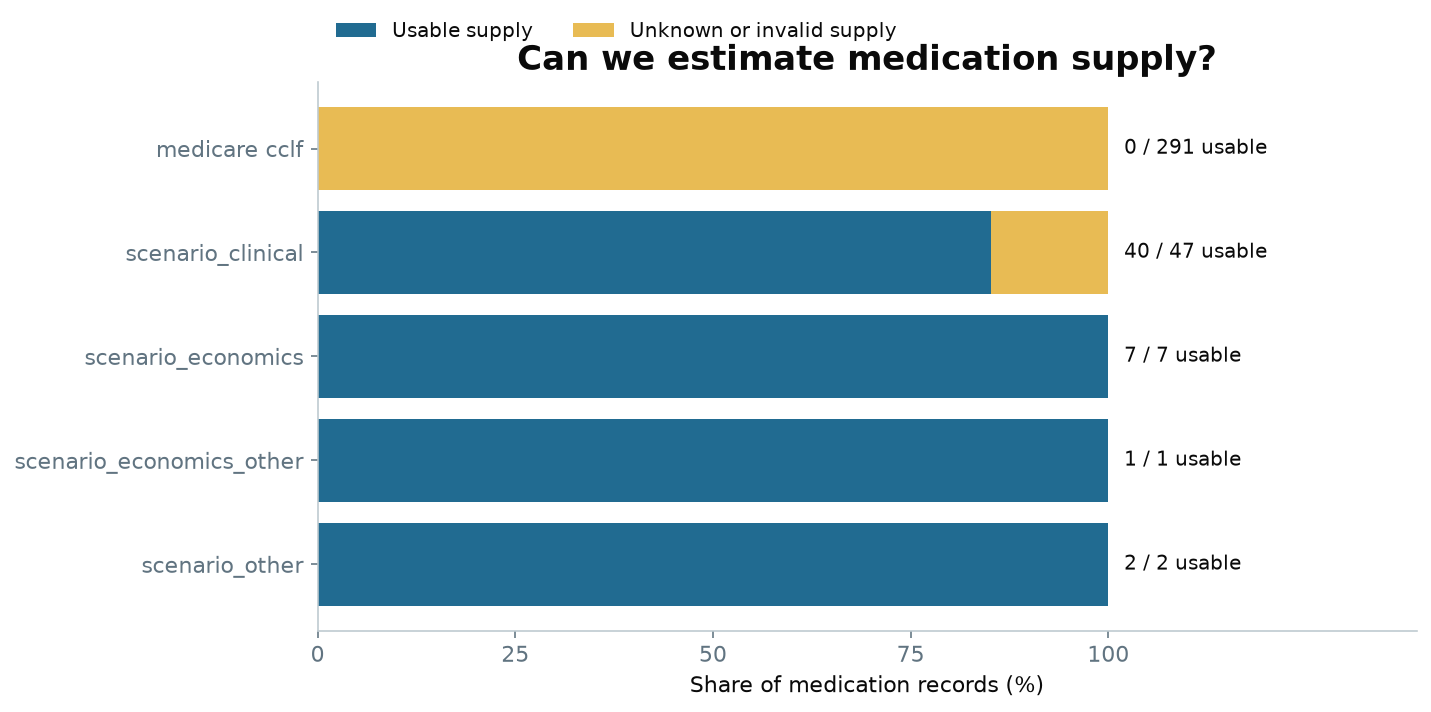

In [5]:
df = as_pandas(exposure_quality_result)
if df.empty:
    no_rows('No claims-derived medications were loaded.')
else:
    totals = df.groupby('data_source')['medication_records'].sum()
    usable = df.loc[df.exposure_status.eq('usable')].groupby('data_source')['medication_records'].sum()
    chart = pd.DataFrame({'total': totals, 'usable': usable}).fillna(0).sort_index()
    chart['unknown_or_invalid'] = chart.total - chart.usable
    fig, ax = plt.subplots(figsize=(10, max(3.2, len(chart) * .65 + 1.8)))
    y = np.arange(len(chart))
    usable_pct = 100 * chart.usable / chart.total
    ax.barh(y, usable_pct, color=BLUE, label='Usable supply')
    ax.barh(y, 100 - usable_pct, left=usable_pct, color='#e8bb54', label='Unknown or invalid supply')
    for i, row in enumerate(chart.itertuples()):
        ax.text(102, i, f'{int(row.usable):,} / {int(row.total):,} usable', va='center', fontsize=10)
    ax.set(yticks=y, yticklabels=[wrap(x, 30) for x in chart.index], xlim=(0, 139),
           xlabel='Share of medication records (%)', title='Can we estimate medication supply?')
    ax.set_xticks([0, 25, 50, 75, 100])
    ax.legend(loc='lower left', bbox_to_anchor=(0, 1.04), ncol=2, frameon=False, fontsize=10)
    ax.invert_yaxis()
    finish(fig, 'Unknown days supply is a data limitation. It does not mean the patient stopped treatment or needs a refill.')


**Saved synthetic example.** All 291 published pharmacy records lack days
supply. They remain visible, but none supplies an episode or a current
exposure estimate. Their latest file date is in 2018 even though the
records were ingested later. The 2026 scenarios supply the known durations
used in the examples below. The `scenario_no_rx` source has no pharmacy
records, so it is absent from the pharmacy-only audit rather than appearing
as a source with zero medication use.


File date describes the delivered source file; ingestion time describes when
it was loaded. A recent reload does not make an old file current. The latest
dispensing date is a separate clinical observation. None of these dates
certifies that the claims feed is complete.

The patient lists carry their own condition and medication evidence dates.
The source can be current even when one patient's latest evidence is old.
Missing duration or unmapped recent medication can make an assessment unknown;
those patients are not silently counted as confirmed gaps.


## 1. Drug Episodes: reconstruct a course of treatment

An episode groups observed supply for the same atomic RxNorm ingredient.
Strength, form and brand changes do not by themselves start a new episode.
A combination pill contributes to each ingredient, so changing between a
combination and its individual components can preserve continuity.

A 30-day fill on January 1 ends January 30. A January 31 refill leaves no
uncovered day; a February 1 refill leaves one. The default permits up to 30
uncovered days inside an episode; 31 starts another episode. This tolerance
describes continuity of a treatment course. It does not turn an uncovered day
into active supply.

Overlapping fills are unioned by default. Optional stockpiling carries supply
only within the same clinical product. `covered_days` and `uncovered_days`
make the distinction between estimated supply and the full episode span
explicit. The end date is the last estimated supply day, without adding the
permissible gap window.

The long table below samples up to eight episodes per source, prioritizing
episodes with uncovered days and observed restarts so their boundaries are
visible. `drug_code` is an RxNorm IN code and `drug_name` is the ingredient name.


In [6]:
WITH ranked AS (
    SELECT episode_id, data_source, person_id, drug_code, drug_name,
           start_date, end_date, fill_count, covered_days, uncovered_days,
           active_supply_flag, assessment_date,
           ROW_NUMBER() OVER (
               PARTITION BY data_source
               ORDER BY uncovered_days DESC, restart_flag DESC,
                        person_id, drug_name, start_date, episode_id
           ) AS sample_rank
    FROM drugs.drug_episode
)
SELECT episode_id, data_source, person_id, drug_code, drug_name,
       start_date, end_date, fill_count, covered_days, uncovered_days,
       active_supply_flag, assessment_date
FROM ranked
WHERE sample_rank <= 8
ORDER BY data_source, person_id, drug_name, start_date;


episode_id,data_source,person_id,drug_code,drug_name,start_date,end_date,fill_count,covered_days,uncovered_days,active_supply_flag,assessment_date
db4aa4a530b2aa8121e6d9c53a832f7e,scenario_clinical,sc_afib_current,1037042,dabigatran etexilate,2026-09-20,2026-11-18,2,60,0,1,2026-11-10
d21f7020c7448ed87c5632cc159984db,scenario_clinical,sc_afib_overdue,1037042,dabigatran etexilate,2026-09-01,2026-10-30,2,60,0,0,2026-11-10
f0c9ae9d3d60495841392caef799098c,scenario_clinical,sc_asthma_current,88249,montelukast,2026-09-20,2026-11-18,2,60,0,1,2026-11-10
c1ea4bd9b917e52396be97d07e9fe917,scenario_clinical,sc_asthma_overdue,88249,montelukast,2026-09-01,2026-10-30,2,60,0,0,2026-11-10
f563b29d2989355e388b4fab95c85b9a,scenario_clinical,sc_asthma_rescue,435,albuterol,2026-11-01,2026-11-30,1,30,0,1,2026-11-10
436b838ed15cdf23dcd1d4f7b00f36b8,scenario_clinical,sc_asthma_rescue,88249,montelukast,2026-09-01,2026-10-30,2,60,0,0,2026-11-10
4ca4f4b12f5c670640259e08355231b5,scenario_clinical,sc_episode_boundary,29046,lisinopril,2026-01-01,2026-04-19,3,79,30,0,2026-11-10
326071fd178cf3371e670af1cad667a7,scenario_clinical,sc_episode_boundary,29046,lisinopril,2026-05-21,2026-06-19,1,30,0,0,2026-11-10
f008a3c63ded6862fa68d1c5e5ead46f,scenario_economics,sc_brand_a,83367,atorvastatin,2026-10-20,2026-11-18,1,30,0,1,2026-11-10
146d0f16f7c943c329f52f718e2bd288,scenario_economics,sc_brand_b,83367,atorvastatin,2026-10-20,2026-11-18,1,30,0,1,2026-11-10


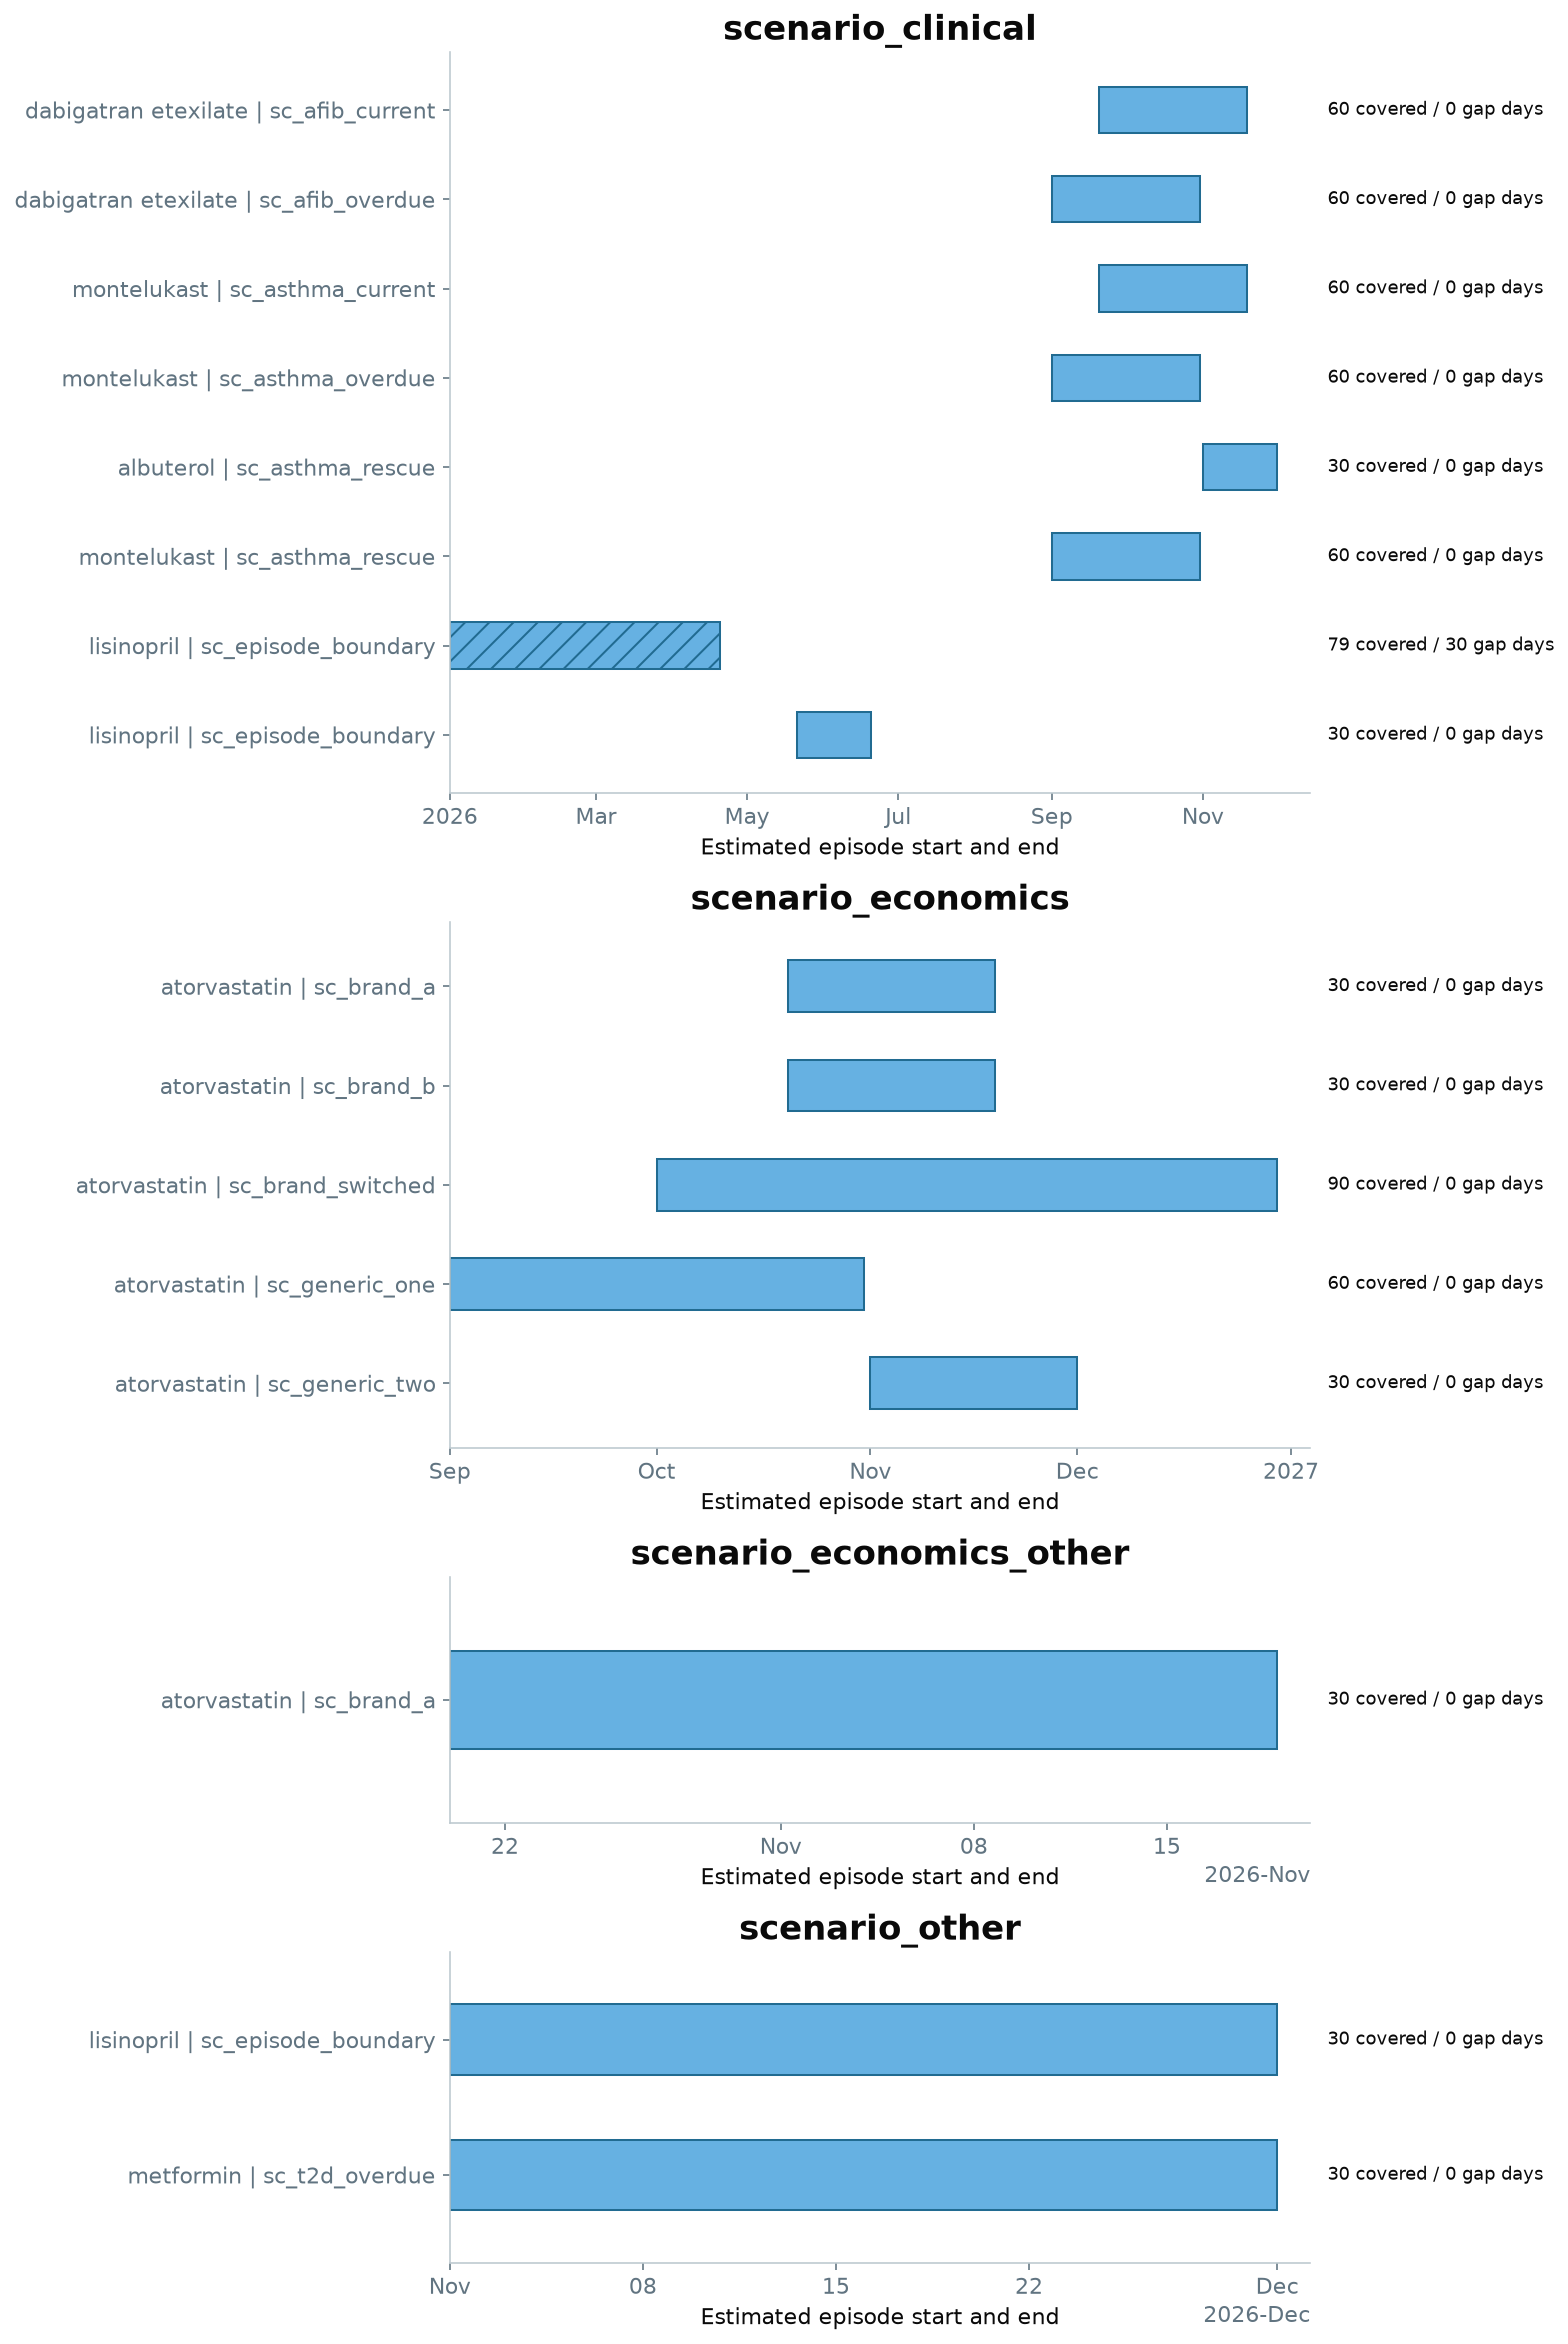

In [7]:
df = as_pandas(episodes_result)
if not clinical_enabled():
    enterprise_required('Drug Episodes')
elif df.empty:
    no_rows('Usable dispensing intervals and ingredient mappings are needed to construct an episode.')
else:
    df['start_date'] = pd.to_datetime(df.start_date)
    df['end_date'] = pd.to_datetime(df.end_date)
    sources = sorted(df.data_source.unique())
    panel_heights = [max(2.2, len(df[df.data_source.eq(s)]) * .64 + 1.5) for s in sources]
    fig, axes = plt.subplots(len(sources), 1, figsize=(11, sum(panel_heights)),
                             gridspec_kw={'height_ratios': panel_heights}, squeeze=False)
    for ax, source in zip(axes[:, 0], sources):
        part = df.loc[df.data_source.eq(source)].reset_index(drop=True)
        start = mdates.date2num(part.start_date)
        duration = (part.end_date - part.start_date).dt.days + 1
        for i, row in part.iterrows():
            ax.barh(i, duration.iloc[i], left=start[i], height=.52, color=SKY,
                    edgecolor=BLUE, hatch='//' if row.uncovered_days > 0 else None)
            ax.text(1.02, i, f'{int(row.covered_days)} covered / {int(row.uncovered_days)} gap days',
                    transform=ax.get_yaxis_transform(), va='center', fontsize=9, clip_on=False)
        ax.set(yticks=np.arange(len(part)),
               yticklabels=[wrap(f'{r.drug_name} | {r.person_id}', 42) for r in part.itertuples()],
               title=wrap(source, 80), xlabel='Estimated episode start and end')
        locator = mdates.AutoDateLocator(minticks=3, maxticks=7)
        ax.xaxis.set_major_locator(locator)
        ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
        ax.margins(x=.04)
        ax.set_ylim(-.65, len(part) - .35)
        ax.invert_yaxis()
    finish(fig, 'Bars show sampled episode spans, which can contain uncovered days. Hatching marks episodes with a gap; it does not identify the exact gap dates. Separate panels preserve each source’s time scale.')


**Saved synthetic example.** The lisinopril course for `sc_episode_boundary`
in `scenario_clinical` runs from January 1 through April 19: **79 covered days
and 30 uncovered days** within one episode. The next fill starts May 21,
after 31 uncovered days, so it starts another episode. The same patient ID
in `scenario_other` stays separate. These rows illustrate the continuity
rule, overlap handling and source-scoped identity; they do not prove ingestion.


In [8]:
SELECT *
FROM drugs.episode_mapping_quality
ORDER BY data_source;


data_source,medication_claim_count,usable_supply_claim_count,ingredient_mapped_claim_count,usable_claims_without_ingredient,unusable_supply_claim_count
medicare cclf,291,0,0,0,291
scenario_clinical,47,40,40,0,7
scenario_economics,7,7,7,0,0
scenario_economics_other,1,1,1,0,0
scenario_other,2,2,2,0,0


## 2. Open Drug Gaps: find absence of current treatment evidence

The mart starts with recent, unresolved Tuva-grouper conditions in
`core.condition`: type 2 diabetes, hypertension, coronary artery disease,
COPD, asthma, heart failure and atrial fibrillation/flutter. The default
lookback is 365 days. A potential open gap means there is no qualifying
related supply active at the assessment date and the available evidence is
sufficient to make that assessment.

This is an **any-related-treatment** question. It does not evaluate every
component of guideline treatment. A rescue inhaler can count as treatment
evidence for asthma; a beta blocker can count for AFib without establishing
stroke prevention. Unknown exposure stays visible in `condition_status`,
with a null gap flag rather than an asserted gap.

Start with counts by condition, then inspect the people behind a count.
Larger counts identify more review candidates; they do not by themselves
show a higher rate or a worse-performing care team.


In [9]:
SELECT condition_code, condition_name,
       SUM(patients_with_open_gaps) AS patients_with_open_gaps,
       SUM(gap_unassessable_patients) AS gap_unassessable_patients,
       SUM(current_record_gap_patients) AS current_record_gap_patients
FROM drugs.condition_summary
GROUP BY condition_code, condition_name
ORDER BY patients_with_open_gaps DESC, condition_name;


condition_code,condition_name,patients_with_open_gaps,gap_unassessable_patients,current_record_gap_patients
asthma,Asthma,2,1,2
afib,Atrial Fibrillation and Flutter,2,1,2
copd,Chronic Obstructive Pulmonary Disease,2,1,2
cad,Coronary Artery Disease,2,1,2
chf,Heart Failure,2,1,2
htn,Hypertension,2,1,2
t2d,Type 2 Diabetes Mellitus,2,2,2


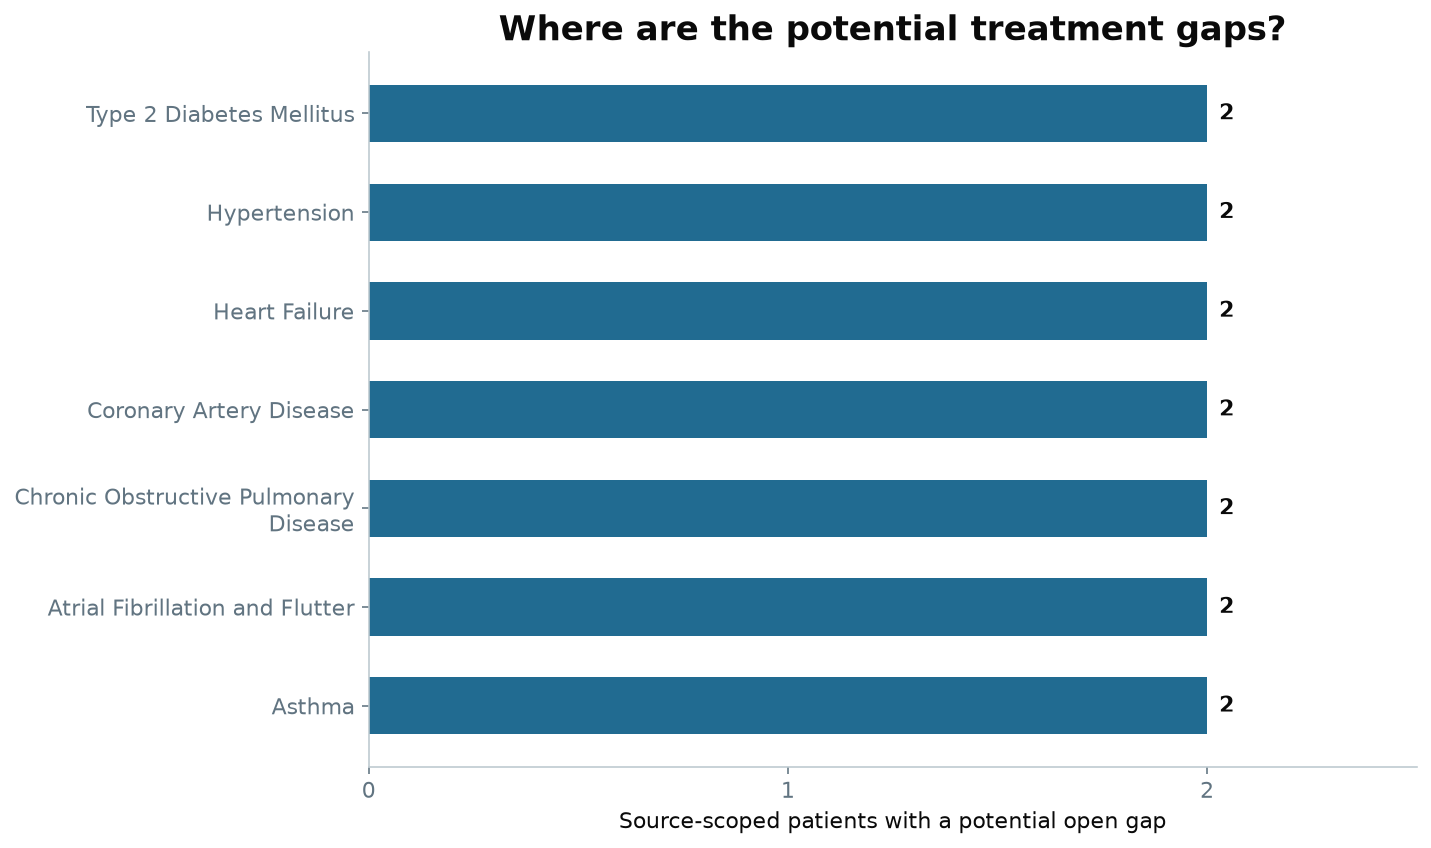

In [10]:
df = as_pandas(gap_counts_result).sort_values(['patients_with_open_gaps', 'condition_name'])
if not clinical_enabled():
    enterprise_required('Open Drug Gaps')
elif df.empty:
    no_rows('No qualifying condition evidence is present in the configured lookback.')
else:
    fig, ax = plt.subplots(figsize=(10, max(4, len(df) * .64 + 1.5)))
    y = np.arange(len(df))
    ax.barh(y, df.patients_with_open_gaps, color=BLUE, height=.58)
    for i, row in enumerate(df.itertuples()):
        ax.annotate(f'{int(row.patients_with_open_gaps):,}', (row.patients_with_open_gaps, i),
                    xytext=(6, 0), textcoords='offset points', va='center', fontweight='bold')
    ax.set(yticks=y, yticklabels=[wrap(x, 36) for x in df.condition_name],
           xlabel='Source-scoped patients with a potential open gap',
           title='Where are the potential treatment gaps?')
    ax.set_xlim(0, max(1, df.patients_with_open_gaps.max()) * 1.25)
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    finish(fig, 'Unknown assessments are excluded from gap counts and reported separately in the table. A person can have several conditions, so condition counts should not be added to estimate unique patients.')


**Saved synthetic example.** Each of the seven conditions has two potential
gaps by construction: one patient with no prior qualifying fill and one
with prior treatment but no current supply. The equal bars are a validation
pattern, not an observed prevalence pattern. Patients with unknown exposure
remain in the unassessable counts instead of being added to the gap worklist.


### From a condition count to the underlying patients

The next query chooses the condition with the largest gap count and returns
up to 20 review candidates across all sources. It retains the diagnosis date,
treatment history and freshness. Current enrollment is a review context;
unconfirmed enrollment does not disappear from the worklist. Known deceased
patients are excluded.


In [11]:
WITH selected_condition AS (
    SELECT condition_code
    FROM drugs.condition_summary
    GROUP BY condition_code
    HAVING SUM(patients_with_open_gaps) > 0
    ORDER BY SUM(patients_with_open_gaps) DESC, condition_code
    LIMIT 1
)
SELECT g.data_source, g.person_id, g.condition_code, g.condition_name,
       g.last_condition_date, g.gap_history,
       g.condition_freshness_date, g.patient_rx_freshness_date,
       g.source_rx_freshness_date, g.source_clinical_lag_days,
       g.outreach_readiness_status
FROM drugs.open_drug_gap g
JOIN selected_condition s ON g.condition_code = s.condition_code
ORDER BY CASE WHEN g.outreach_readiness_status = 'current_record_review' THEN 0 ELSE 1 END,
         g.data_source, g.person_id
LIMIT 20;


data_source,person_id,condition_code,condition_name,last_condition_date,gap_history,condition_freshness_date,patient_rx_freshness_date,source_rx_freshness_date,source_clinical_lag_days,outreach_readiness_status
scenario_clinical,sc_afib_never,afib,Atrial Fibrillation and Flutter,2026-10-01,no_prior_qualifying_claim,2026-11-10,—,2026-11-10,9,current_record_review
scenario_clinical,sc_afib_overdue,afib,Atrial Fibrillation and Flutter,2026-10-01,prior_treatment_now_without_active_supply,2026-11-10,2026-11-10,2026-11-10,9,current_record_review


## 3. Needs Refill: distinguish established treatment from an open gap

A refill recommendation needs more history than the absence of treatment.
By default, the mart requires at least two distinct maintenance dispensing
dates in the past 365 days. The due date is the day after estimated
maintenance supply ends. Candidates are due within seven days or are no more
than 30 days overdue, without unresolved exposure uncertainty.

A patient due soon may still have active supply and no open gap. A recently
overdue patient can appear in both lists. More distant gaps remain candidates
for treatment review rather than automatic restart. Current maintenance
replacement therapy suppresses overdue refill recommendations. Rescue-only
respiratory medication does not by itself suppress an overdue controller
refill; it can still close the broader any-treatment gap flag.

### Use the condition population as the denominator

`refill_denominator_patients` includes living patients with qualifying
condition evidence in sources that have an observed pharmacy feed. It
includes people without prior fills and those with uncertain exposure. Thus,
the percentage describes the share flagged for refill review, **not the share
adherent or adequately treated**. Sources without pharmacy observations are
excluded from this denominator.

Across sources, add the patient counts and denominators before dividing.
Averaging source-level percentages would give a small source the same weight
as a large one. The following query returns the numerator, denominator and
percentage together.


In [12]:
SELECT condition_code, condition_name,
       SUM(patients_needing_refill) AS patients_needing_refill,
       SUM(refill_denominator_patients) AS number_with_condition,
       ROUND(100.0 * SUM(patients_needing_refill)
             / NULLIF(SUM(refill_denominator_patients), 0), 2)
           AS percent_needing_refill,
       SUM(refill_unassessable_patients) AS refill_unassessable_patients
FROM drugs.condition_summary
GROUP BY condition_code, condition_name
ORDER BY patients_needing_refill DESC, condition_name;


condition_code,condition_name,patients_needing_refill,number_with_condition,percent_needing_refill,refill_unassessable_patients
asthma,Asthma,2,5,40.00,1
htn,Hypertension,2,5,40.00,1
afib,Atrial Fibrillation and Flutter,1,4,25.00,1
copd,Chronic Obstructive Pulmonary Disease,1,4,25.00,1
cad,Coronary Artery Disease,1,4,25.00,1
chf,Heart Failure,1,5,20.00,1
t2d,Type 2 Diabetes Mellitus,1,5,20.00,2


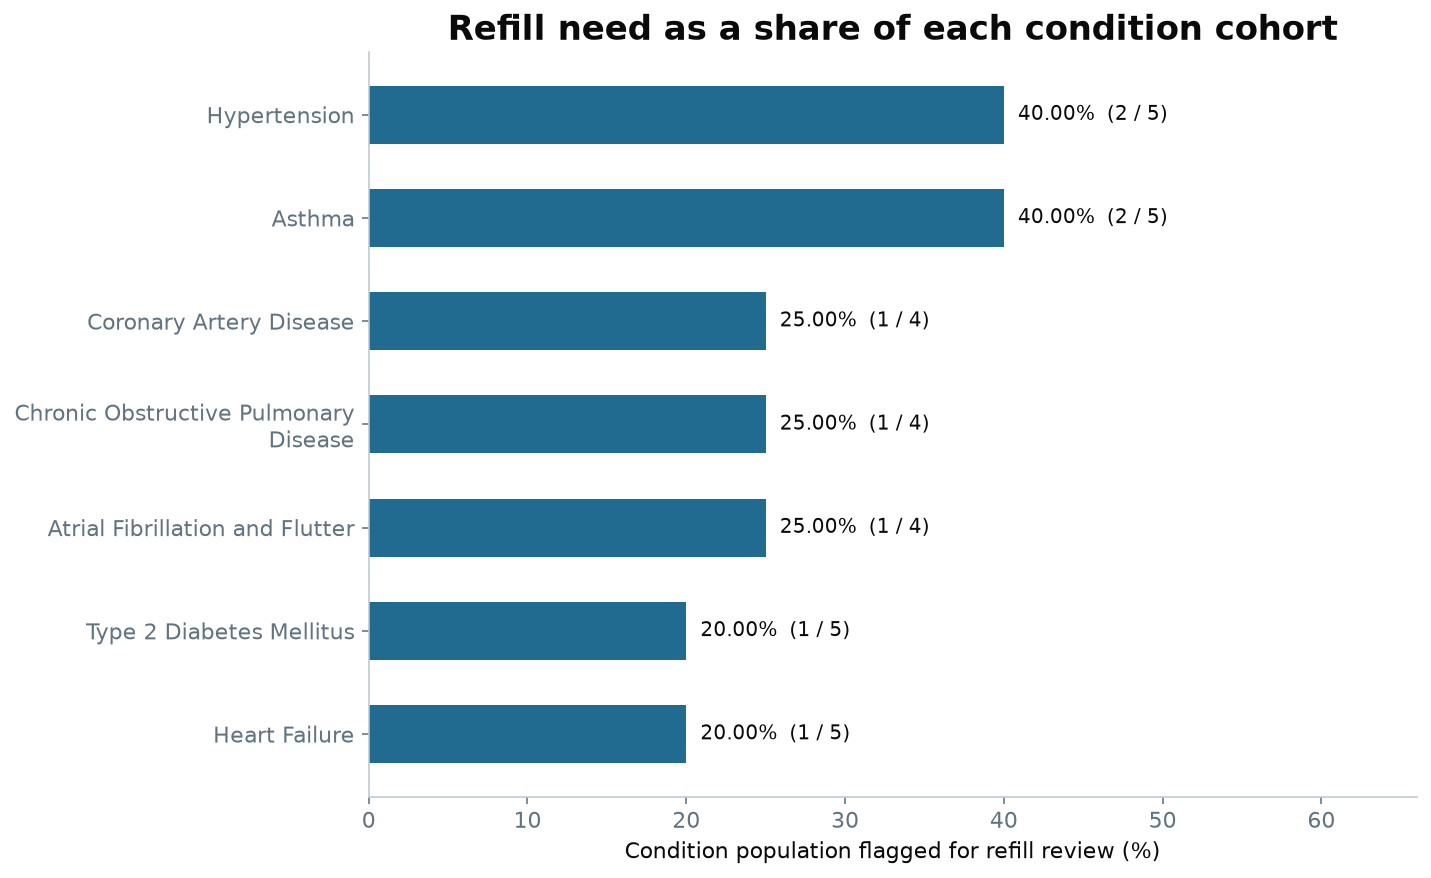

In [13]:
df = as_pandas(refill_counts_result).sort_values(['percent_needing_refill', 'condition_name'], na_position='first')
if not clinical_enabled():
    enterprise_required('Needs Refill')
elif df.empty:
    no_rows('No qualifying condition population is present.')
else:
    fig, ax = plt.subplots(figsize=(10, max(4, len(df) * .67 + 1.5)))
    values = pd.to_numeric(df.percent_needing_refill, errors='coerce')
    y = np.arange(len(df))
    ax.barh(y, values.fillna(0), color=BLUE, height=.56)
    for i, row in enumerate(df.itertuples()):
        if pd.isna(row.percent_needing_refill):
            label, x = 'No eligible denominator', 0
        else:
            label, x = f'{row.percent_needing_refill:.2f}%  ({int(row.patients_needing_refill):,} / {int(row.number_with_condition):,})', row.percent_needing_refill
        ax.annotate(label, (x, i), xytext=(7, 0), textcoords='offset points', va='center', fontsize=10)
    max_pct = values.max() if values.notna().any() else 0
    ax.set(yticks=y, yticklabels=[wrap(x, 36) for x in df.condition_name],
           xlabel='Condition population flagged for refill review (%)',
           title='Refill need as a share of each condition cohort')
    ax.set_xlim(0, max(10, max_pct * 1.65))
    finish(fig, 'Labels show the flagged count divided by the condition denominator. Unknown exposure remains in the denominator, so low percentages can reflect incomplete data rather than successful medication management.')


**Saved synthetic example.** Asthma and hypertension each show **2 of 5
patients (40%)** flagged. The asthma drilldown includes a patient with
current albuterol supply and overdue montelukast supply: rescue treatment
can close the broad open-gap flag without hiding a potential maintenance
refill. The source-level table also shows why T2D's combined percentage is
20%: one flagged patient across five qualifying source-scoped patients.
The no-pharmacy source contributes no refill denominator and has a null
percentage. These small constructed cohorts illustrate denominator behavior.


In [14]:
SELECT data_source, condition_name, patients_needing_refill,
       refill_denominator_patients, percent_needing_refill,
       refill_unassessable_patients
FROM drugs.condition_summary
ORDER BY data_source, condition_name;


data_source,condition_name,patients_needing_refill,refill_denominator_patients,percent_needing_refill,refill_unassessable_patients
scenario_clinical,Asthma,2,5,40.00,1
scenario_clinical,Atrial Fibrillation and Flutter,1,4,25.00,1
scenario_clinical,Chronic Obstructive Pulmonary Disease,1,4,25.00,1
scenario_clinical,Coronary Artery Disease,1,4,25.00,1
scenario_clinical,Heart Failure,1,5,20.00,1
scenario_clinical,Hypertension,2,5,40.00,1
scenario_clinical,Type 2 Diabetes Mellitus,1,4,25.00,1
scenario_no_rx,Type 2 Diabetes Mellitus,0,0,—,1
scenario_other,Type 2 Diabetes Mellitus,0,1,0.00,0


### Review the due date and the fill that produced it

The next list starts with the condition with the most refill candidates.
`drug_associated_with_refill_due_date` is the maintenance fill whose supply
end determines the due date, which is not necessarily the latest dispensing
date. Negative days overdue means due soon; zero means due on the assessment
date. Confirm that the treatment is still intended and scheduled before
acting, especially when the source is lagged.


In [15]:
WITH selected_condition AS (
    SELECT condition_code
    FROM drugs.condition_summary
    GROUP BY condition_code
    HAVING SUM(patients_needing_refill) > 0
    ORDER BY SUM(patients_needing_refill) DESC, condition_code
    LIMIT 1
)
SELECT r.data_source, r.person_id, r.condition_name,
       r.latest_maintenance_medication_id,
       r.latest_maintenance_drug_name AS drug_associated_with_refill_due_date,
       r.maintenance_fill_dates, r.estimated_refill_due_date,
       r.days_overdue, r.refill_status,
       r.treatment_evidence_file_date, r.treatment_evidence_ingest_datetime,
       r.source_rx_freshness_date, r.outreach_readiness_status
FROM drugs.needs_refill r
JOIN selected_condition s ON r.condition_code = s.condition_code
ORDER BY CASE WHEN r.outreach_readiness_status = 'current_record_review' THEN 0 ELSE 1 END,
         r.days_overdue DESC, r.data_source, r.person_id
LIMIT 20;


data_source,person_id,condition_name,latest_maintenance_medication_id,drug_associated_with_refill_due_date,maintenance_fill_dates,estimated_refill_due_date,days_overdue,refill_status,treatment_evidence_file_date,treatment_evidence_ingest_datetime,source_rx_freshness_date,outreach_readiness_status
scenario_clinical,sc_asthma_overdue,Asthma,sc_asthma_overdue_asthma_20261001-1-scenario_clinical,montelukast 10 MG Oral Tablet,2,2026-10-31,10,overdue,2026-11-10,2026-11-10 08:00:00,2026-11-10,current_record_review
scenario_clinical,sc_asthma_rescue,Asthma,sc_asthma_rescue_asthma_20261001-1-scenario_clinical,montelukast 10 MG Oral Tablet,2,2026-10-31,10,overdue,2026-11-10,2026-11-10 08:00:00,2026-11-10,current_record_review


## 4. Brand vs. Generic: separate availability from a priced opportunity

The starting population is patients with branded supply active at the
assessment date, counted once per source, patient and clinical product.
The generic alternative shares the clinical drug: ingredient, strength and
form. Availability does not establish therapeutic equivalence, coverage or
appropriateness for an individual patient.

Enterprise marketing fields require known
categories to be NDA for current brands and ANDA for generic alternatives.
Generics also need valid known marketing dates; a brand fill can remain
on hand after its marketing end date. A missing category retains the baseline
comparison, with known generic dates still checked. Open uses active product
flags without these paid checks. Inspect the screening basis
rather than assuming every paid deployment applied all regulatory checks.

Prices come from **payer-paid amounts only**. The generic benchmark is the
median paid price per unit over the previous 90 days, matched on source,
payer, plan, clinical product and quantity per supply day. Defaults require
three generic claims and two people. Missing prices remain unknown.

Financial outputs are rounded independently to cents from the daily amounts;
do not derive the annual estimate from a rounded 30-day value.

The estimate holds the patient's quantity per day constant and compares the
observed brand price with that generic benchmark. Annual savings assume 365
days of continued treatment at the same dose and prices; rebates, switching
costs and future treatment changes are not modeled.


In [16]:
SELECT generic_screening_basis, enterprise_marketing_enabled_flag,
       marketing_screening_applied_flag,
       COUNT(*) AS generic_package_alternatives
FROM drugs.generic_alternative
GROUP BY generic_screening_basis, enterprise_marketing_enabled_flag,
         marketing_screening_applied_flag
ORDER BY generic_screening_basis;


generic_screening_basis,enterprise_marketing_enabled_flag,marketing_screening_applied_flag,generic_package_alternatives
active_product_flags,1,0,64987
enterprise_marketing_metadata,1,1,107223


In [17]:
SELECT brand_drug, clinical_drug_id, generic_alternative,
       SUM(patients_who_could_switch) AS patients_who_could_switch,
       SUM(patients_with_savings_estimate) AS patients_with_savings_estimate,
       SUM(patients_without_savings_estimate) AS patients_without_savings_estimate,
       ROUND(SUM(annual_savings_for_priced_patients), 2)
           AS annual_savings_for_priced_patients,
       CASE WHEN SUM(patients_without_savings_estimate) = 0
            THEN ROUND(SUM(annual_savings_for_priced_patients), 2)
       END AS annual_savings_if_all_switched
FROM drugs.brand_generic_summary
GROUP BY brand_drug, clinical_drug_id, generic_alternative
ORDER BY annual_savings_for_priced_patients DESC NULLS LAST,
         brand_drug, clinical_drug_id;


brand_drug,clinical_drug_id,generic_alternative,patients_who_could_switch,patients_with_savings_estimate,patients_without_savings_estimate,annual_savings_for_priced_patients,annual_savings_if_all_switched
atorvastatin 20 MG Oral Tablet [Lipitor],617310,atorvastatin 20 MG Oral Tablet,3,2,1,"2,336.00",—


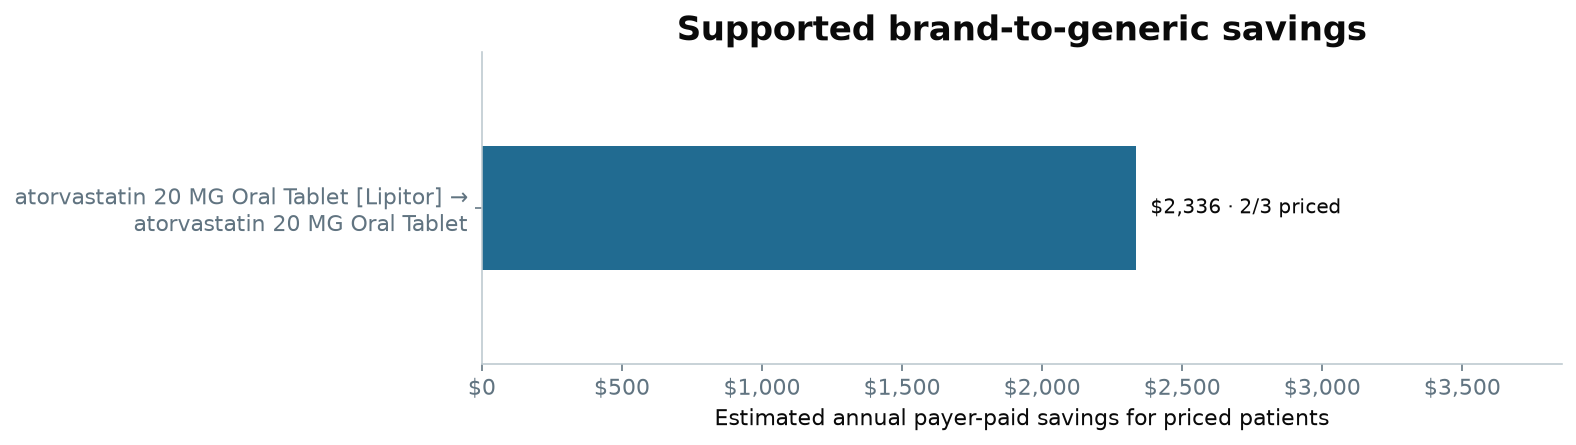

In [18]:
df = as_pandas(brand_generic_result)
if df.empty:
    no_rows('No current brand users with a catalog generic alternative met the opportunity definition.')
else:
    chart = df.sort_values('annual_savings_for_priced_patients', ascending=False, na_position='last').head(10).iloc[::-1].copy()
    values = pd.to_numeric(chart.annual_savings_for_priced_patients, errors='coerce')
    fig, ax = plt.subplots(figsize=(11, max(3.2, len(chart) * 1.05 + 1.5)))
    y = np.arange(len(chart))
    ax.barh(y, values.fillna(0), color=BLUE, height=.52)
    for i, row in enumerate(chart.itertuples()):
        priced, candidates = int(row.patients_with_savings_estimate), int(row.patients_who_could_switch)
        if pd.isna(row.annual_savings_for_priced_patients):
            label, x = f'No supported estimate · {candidates} candidates', 0
        else:
            label, x = f'${row.annual_savings_for_priced_patients:,.0f} · {priced}/{candidates} priced', row.annual_savings_for_priced_patients
        ax.annotate(label, (x, i), xytext=(7, 0), textcoords='offset points', va='center', fontsize=10)
    labels = [wrap(f'{r.brand_drug} → {r.generic_alternative}', 46) for r in chart.itertuples()]
    max_value = values.max() if values.notna().any() else 0
    ax.set(yticks=y, yticklabels=labels, xlabel='Estimated annual payer-paid savings for priced patients',
           title='Supported brand-to-generic savings')
    ax.set_xlim(0, max(1, max_value) * 1.65)
    ax.set_ylim(-.65, len(chart) - .35)
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f'${v:,.0f}'))
    finish(fig, 'The chart shows the priced subtotal for up to ten clinical products. It is not an estimate for unpriced patients. Use annual_savings_if_all_switched only when every candidate has a supported price.')


**Saved synthetic example.** Three current Lipitor 20 mg users have a matching
generic atorvastatin product. Two have a supported benchmark, producing
**$2,336 in annualized payer-paid savings** for the priced subset. The third
is in a separate source without comparable paid generic claims. Its savings
remain unknown, so the all-patients-switched estimate is null. This distinction
prevents a partial subtotal from being presented as the opportunity for everyone.


### Keep the benchmark evidence with the estimated savings

The patient/product table below shows why an opportunity is priced or
unpriced, the number of comparable generic claims and people, and the source
freshness. Aggregate this parent table before joining the one-to-many list of
generic NDCs; otherwise, alternative packages would multiply patient counts
and dollars.


In [19]:
SELECT data_source, person_id, drug_name AS brand_drug,
       clinical_drug_name, generic_alternative_name,
       generic_ndc_count, pricing_status,
       benchmark_claim_count, benchmark_person_count,
       benchmark_first_fill_date, benchmark_last_fill_date,
       estimated_savings_per_30_days, estimated_annual_savings,
       brand_file_date, benchmark_file_date, source_rx_freshness_date,
       outreach_readiness_status
FROM drugs.brand_generic_opportunity
WHERE generic_available_flag = 1
ORDER BY estimated_annual_savings DESC NULLS LAST, data_source, person_id, clinical_drug_id
LIMIT 20;


data_source,person_id,brand_drug,clinical_drug_name,generic_alternative_name,generic_ndc_count,pricing_status,benchmark_claim_count,benchmark_person_count,benchmark_first_fill_date,benchmark_last_fill_date,estimated_savings_per_30_days,estimated_annual_savings,brand_file_date,benchmark_file_date,source_rx_freshness_date,outreach_readiness_status
scenario_economics,sc_brand_a,atorvastatin 20 MG Oral Tablet [Lipitor],atorvastatin 20 MG Oral Tablet,atorvastatin 20 MG Oral Tablet,396,priced_for_review,4.00,3.00,2026-09-01,2026-11-01,111.00,"1,350.50",2026-11-10,2026-11-10,2026-11-10,current_record_review
scenario_economics,sc_brand_b,atorvastatin 20 MG Oral Tablet [Lipitor],atorvastatin 20 MG Oral Tablet,atorvastatin 20 MG Oral Tablet,396,priced_for_review,4.00,3.00,2026-09-01,2026-11-01,81.00,985.50,2026-11-10,2026-11-10,2026-11-10,current_record_review
scenario_economics_other,sc_brand_a,atorvastatin 20 MG Oral Tablet [Lipitor],atorvastatin 20 MG Oral Tablet,atorvastatin 20 MG Oral Tablet,396,insufficient_paid_benchmark,—,—,—,—,—,—,2026-11-10,—,2026-11-10,current_record_review


## Use the results to organize a review

For patient support, start with a condition's count and inspect the people,
fill history and freshness behind it. Separate uncertain evidence from an
assessed potential gap. A refill list is condition-level; another active
maintenance treatment can hide a missing component of a multidrug regimen.
Neither a zero flag nor absence from a worklist proves appropriate treatment.

For medical economics, distinguish the number with a catalog alternative from
the number with a defensible price estimate. Review the generic relationship,
formulary and benefit context before treating an estimate as achievable
savings. Keep source, patient and clinical-product keys intact when joining.

The episode method is informed by [OHDSI drug eras](https://ohdsi.github.io/CommonDataModel/cdm54.html#drug_era)
and [AdhereR](https://doi.org/10.1371/journal.pone.0174426). The mart's defaults
are configurable analytical assumptions. Its seven-condition ATC rules
identify related treatment, not a complete clinical prescribing protocol.
See the [package methods and configuration](https://github.com/tuva-health/drugs#readme)
for exact definitions and the [CodeRx Drug Database](https://thetuvaproject.com/coderx)
for terminology setup.
